# Partie 5 : extension générative (option B, auto-encodeur variationnel)

Un auto-encodeur variationnel (VAE) apprend à la fois à reconstruire une image et à organiser son code `z` pour qu'on puisse **tirer de nouvelles feuilles au hasard**.

- On entraîne un VAE 64×64 sur les feuilles **saines** d'entraînement, comme l'auto-encodeur de la partie 3, pour que la comparaison soit juste.
- On visualise l'espace latent, on interpole entre deux feuilles et on génère de nouvelles images.
- On compare enfin le VAE à l'auto-encodeur simple comme détecteur d'anomalies (malade contre saine).
- Le test n'est utilisé qu'une seule fois, à la fin. Le coefficient β et le score sont choisis sur la validation.

In [2]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score

from src import config as C
from src import data as D
from src.models import VAE, vae_loss, build_ae
from src.metrics import upsert_summary

C.set_seed(42)
dev = C.DEVICE
print(C.describe_env())

Python 3.12.15, torch 2.14.1+cu126, torchvision 0.29.1+cu126
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 2060 with Max-Q Design
CPU : AMD Ryzen 9 4900HS with Radeon Graphics (16 coeurs logiques)


- On charge les images en 64×64, pixels entre 0 et 1.
- Entraînement : feuilles saines du train. Validation : feuilles saines et malades du val (les feuilles malades ne servent qu'à choisir β et le score, jamais à entraîner).

In [3]:
df = D.load_splits()
healthy = C.HEALTHY_CLASS
diseased = [c for c in D.CLASSES if c != healthy]

def load(split, classes):
    """Images 64x64 d'un split -> tenseur (N, 3, 64, 64) dans [0, 1]."""
    d = D.subset(df, split=split, classes=classes)
    imgs = D.load_cache([C.resolve(p) for p in d["path"]], C.AE_SIZE)
    return torch.from_numpy(np.array(imgs)).permute(0, 3, 1, 2).float().div(255).to(dev)

X_train = load("train", [healthy])
X_val_h = load("val", [healthy])
X_val_d = load("val", diseased)
print("healthy (train) :", tuple(X_train.shape), "| healthy (val) :", tuple(X_val_h.shape), "| diseased (val) :", tuple(X_val_d.shape))

healthy (train) : (1115, 3, 64, 64) | healthy (val) : (237, 3, 64, 64) | diseased (val) : (2487, 3, 64, 64)


## 5.1 Le modèle et la perte

- Le VAE a la même forme que l'auto-encodeur : un encodeur convolutif, un décodeur symétrique. Mais l'encodeur donne **deux** vecteurs de taille `K`, une moyenne `mu` et un `log σ²`.
- On tire `z = mu + σ·ε` avec `ε` aléatoire, et le décodeur reconstruit l'image à partir de `z`.
- Perte = erreur de reconstruction (somme des carrés sur les pixels) + **β × KL**. Le terme KL pousse les codes vers une loi normale centrée : c'est lui qui permet de tirer un `z` au hasard et d'obtenir une feuille plausible.
- β règle le compromis. Petit β : images nettes mais espace latent peu régulier. Grand β : espace régulier mais images floues. On essaie trois valeurs.

In [4]:
K = 32
print(VAE(K))
print(f"{sum(p.numel() for p in VAE(K).parameters()):,} paramètres")

VAE(
  (encoder): Encoder(
    (conv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (8): ReLU(inplace=True)
      (9): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (fc_mu): Linear(in_features=8192, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=8192, out_features=32, bias=True)
  (decoder): Decoder(
    (fc): Linear(in_features=32, out_features=8192, bias=True)
    (deconv): Sequential(
      (0): ConvTranspose

In [5]:
EPOCHS, BATCH, LR = 40, 64, 1e-3
BETAS = [0.1, 1.0, 4.0]
D_PIXELS = 3 * 64 * 64

def train_vae(beta):
    """Entraîne un VAE sur les feuilles saines. Renvoie le modèle, l'historique et la durée."""
    C.set_seed(42)
    t0 = time.time()
    model = VAE(K).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"rec": [], "kl": [], "val_rec": [], "val_kl": []}
    for ep in range(EPOCHS):
        model.train()
        order = torch.randperm(len(X_train), device=dev)
        rec_s, kl_s = 0.0, 0.0
        for i in range(0, len(order), BATCH):
            x = X_train[order[i:i + BATCH]]
            if torch.rand(1) < 0.5: x = x.flip(3)
            if torch.rand(1) < 0.5: x = x.flip(2)
            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            rec_s += rec.item() * len(x); kl_s += kl.item() * len(x)
        model.eval()
        with torch.no_grad():
            x_hat, mu, logvar = model(X_val_h)          # en évaluation, z = mu
            _, vr, vk = vae_loss(x_hat, X_val_h, mu, logvar, beta)
        hist["rec"].append(rec_s / len(X_train)); hist["kl"].append(kl_s / len(X_train))
        hist["val_rec"].append(vr.item()); hist["val_kl"].append(vk.item())
        if (ep + 1) % 10 == 0:
            print(f"beta={beta} epoch {ep + 1}/{EPOCHS}  rec val {vr.item():.1f}  KL val {vk.item():.1f}")
    return model, hist, time.time() - t0

vaes, hists, times = {}, {}, {}
for b in BETAS:
    vaes[b], hists[b], times[b] = train_vae(b)
    print(f"-> beta={b} : {times[b]:.0f} s")

beta=0.1 epoch 10/40  rec val 84.7  KL val 75.5
beta=0.1 epoch 20/40  rec val 75.8  KL val 64.8
beta=0.1 epoch 30/40  rec val 73.9  KL val 71.4
beta=0.1 epoch 40/40  rec val 70.6  KL val 65.1
-> beta=0.1 : 20 s
beta=1.0 epoch 10/40  rec val 100.6  KL val 21.9
beta=1.0 epoch 20/40  rec val 88.0  KL val 20.6
beta=1.0 epoch 30/40  rec val 81.5  KL val 23.4
beta=1.0 epoch 40/40  rec val 79.1  KL val 22.8
-> beta=1.0 : 18 s
beta=4.0 epoch 10/40  rec val 151.6  KL val 5.3
beta=4.0 epoch 20/40  rec val 128.1  KL val 5.4
beta=4.0 epoch 30/40  rec val 124.6  KL val 5.6
beta=4.0 epoch 40/40  rec val 112.5  KL val 6.5
-> beta=4.0 : 18 s


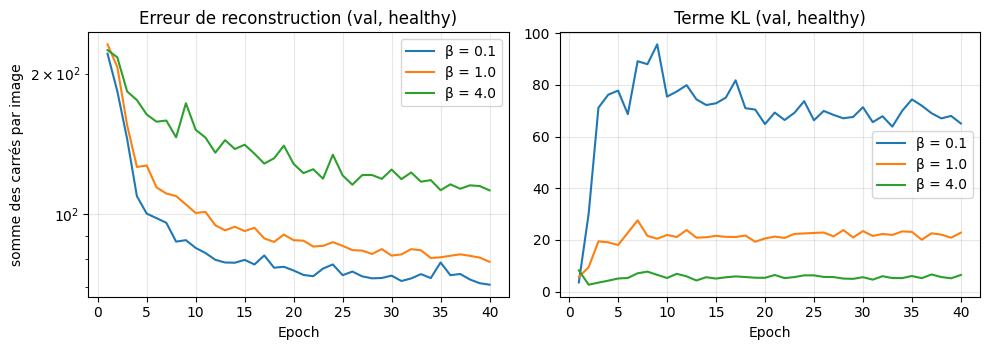

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for b in BETAS:
    ax[0].plot(range(1, EPOCHS + 1), hists[b]["val_rec"], label=f"β = {b}")
    ax[1].plot(range(1, EPOCHS + 1), hists[b]["val_kl"], label=f"β = {b}")
ax[0].set_yscale("log"); ax[0].set_title("Erreur de reconstruction (val, healthy)"); ax[0].set_ylabel("somme des carrés par image")
ax[1].set_title("Terme KL (val, healthy)")
for a in ax:
    a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_vae_courbes.png", dpi=150, bbox_inches="tight"); plt.show()

## 5.2 Reconstructions et images générées

- Ligne du haut : feuilles saines de la validation. Lignes suivantes : leur reconstruction par le VAE de chaque β.
- Dernières lignes : feuilles **inventées**, obtenues en décodant un `z` tiré au hasard dans une loi normale. Aucune image réelle n'est utilisée.

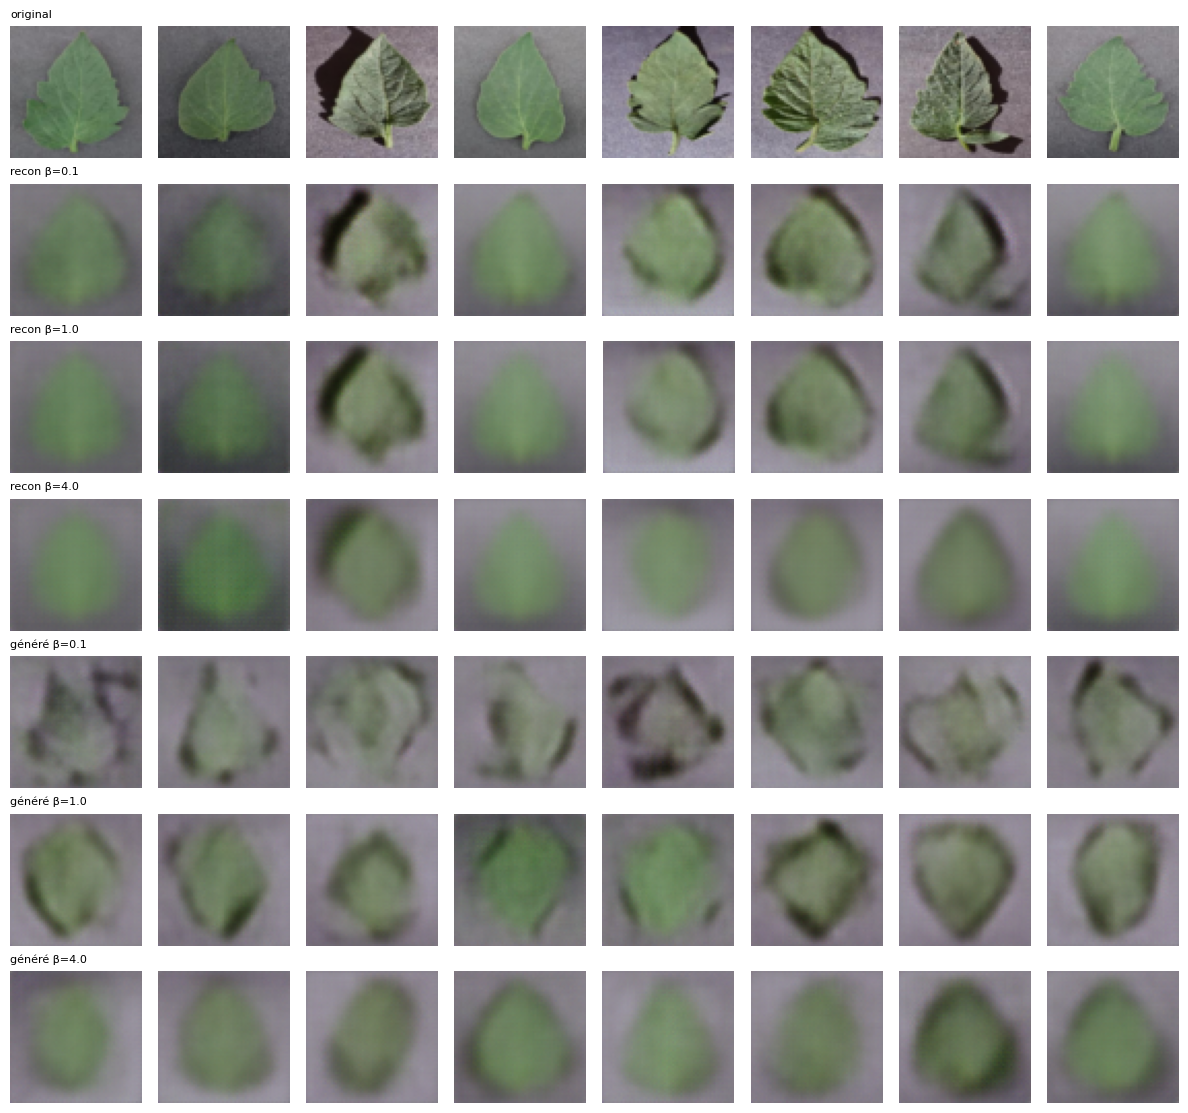

In [7]:
idx = np.linspace(0, len(X_val_h) - 1, 8).astype(int)
x = X_val_h[idx]
lignes = [("original", x)]
with torch.no_grad():
    for b in BETAS:
        lignes.append((f"recon β={b}", vaes[b].eval()(x)[0]))
torch.manual_seed(42)
for b in BETAS:
    lignes.append((f"généré β={b}", vaes[b].eval().sample(8, dev)))

fig, ax = plt.subplots(len(lignes), 8, figsize=(8 * 1.5, len(lignes) * 1.6))
for r, (nom, imgs) in enumerate(lignes):
    for c in range(8):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); ax[r, c].axis("off")
    ax[r, 0].set_title(nom, fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_vae_recon_generation.png", dpi=150, bbox_inches="tight"); plt.show()

### Ce qu'on observe

- **Reconstruction.** Plus β est grand, plus les images sont floues : l'erreur de reconstruction de validation finit à 71 (β = 0,1), 79 (β = 1) et 113 (β = 4). Le terme KL fait l'inverse, 65, 23 puis 6,5. C'est le compromis attendu.
- **Détail perdu.** Les feuilles reviennent sous forme de taches vertes lisses : la forme, la couleur et l'arrière-plan sont conservés, mais les nervures et les motifs de la surface disparaissent. Les zones noires sur les bords de certaines photos (arrière-plan de la photo, pas la feuille) sont reproduites floues.
- **Génération.** Avec β = 0,1, les feuilles inventées sont déchirées et irrégulières : l'espace latent n'est pas assez régulier pour qu'un `z` tiré au hasard tombe dans une zone qui ressemble à une vraie feuille. Avec β = 1, elles ressemblent à des feuilles floues et symétriques. Avec β = 4, ce sont des taches vertes qui se ressemblent beaucoup : il y a peu de diversité d'une image à l'autre.
- **Ce qu'on retient.** Aucune de ces images n'est réaliste : à 64×64 et avec une perte au carré, un VAE donne des images floues. À notre avis, β = 1 est le meilleur compromis visuel (jugement visuel, pas une mesure).

## 5.3 Choix de β et du score d'anomalie (sur la validation)

Un VAE donne trois scores possibles pour dire « cette feuille est anormale » :
- `mse` : erreur de reconstruction moyenne par pixel (comme l'auto-encodeur de la partie 3) ;
- `kl` : distance entre le code de l'image et la loi normale ;
- `elbo` : reconstruction + β × KL, c'est-à-dire la perte d'entraînement de l'image.

On calcule l'AUROC malade contre saine pour chaque β et chaque score, sur la **validation**, et on garde la meilleure combinaison.

In [8]:
@torch.no_grad()
def vae_scores(model, X, beta):
    """Scores par image : mse (par pixel), kl, elbo = somme des carrés + beta·KL."""
    model.eval()
    mse, kl = [], []
    for i in range(0, len(X), 256):
        xb = X[i:i + 256]
        x_hat, mu, logvar = model(xb)
        mse.append(((x_hat - xb) ** 2).flatten(1).mean(1))
        kl.append(-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    mse, kl = torch.cat(mse).cpu().numpy(), torch.cat(kl).cpu().numpy()
    return {"mse": mse, "kl": kl, "elbo": mse * D_PIXELS + beta * kl}

def auroc(s_saines, s_malades):
    y = np.r_[np.zeros(len(s_saines)), np.ones(len(s_malades))]
    return roc_auc_score(y, np.r_[s_saines, s_malades])

auc_val = {}
print(f"{'β':>5s} {'mse':>7s} {'kl':>7s} {'elbo':>7s}   (AUROC validation)")
for b in BETAS:
    sh, sd = vae_scores(vaes[b], X_val_h, b), vae_scores(vaes[b], X_val_d, b)
    for nom in ("mse", "kl", "elbo"):
        auc_val[(b, nom)] = auroc(sh[nom], sd[nom])
    print(f"{b:>5} {auc_val[(b, 'mse')]:>7.3f} {auc_val[(b, 'kl')]:>7.3f} {auc_val[(b, 'elbo')]:>7.3f}")

BETA_BEST, SCORE_BEST = max(auc_val, key=auc_val.get)      # choix sur la validation uniquement
vae = vaes[BETA_BEST]
print(f"Choix : β = {BETA_BEST}, score = {SCORE_BEST} (AUROC val {auc_val[(BETA_BEST, SCORE_BEST)]:.3f})")

    β     mse      kl    elbo   (AUROC validation)
  0.1   0.595   0.802   0.602
  1.0   0.635   0.744   0.657
  4.0   0.663   0.748   0.703
Choix : β = 0.1, score = kl (AUROC val 0.802)


### Ce qu'on observe

| β | mse | kl | elbo |
|---|---|---|---|
| 0,1 | 0,595 | **0,802** | 0,602 |
| 1 | 0,635 | 0,744 | 0,657 |
| 4 | 0,663 | 0,748 | 0,703 |

- **Le meilleur score est le terme KL**, avec β = 0,1 (AUROC validation 0,802). Il est bien meilleur que l'erreur de reconstruction (0,595 à 0,663), qui est le score de la partie 3 (AUROC validation 0,634 pour l'auto-encodeur).
- **L'erreur de reconstruction détecte moins bien quand β est petit.** Avec β = 0,1, le VAE reconstruit mieux toutes les images (erreur de validation la plus basse, 71), y compris les malades : c'est une explication possible de l'AUROC plus faible du score `mse`, que nous n'avons pas vérifiée.
- **Pourquoi le KL marche mieux : une hypothèse, pas vérifiée.** Le KL mesure à quel point le code d'une image est loin de ce que le VAE a appris sur les feuilles saines. Il réagit peut-être à ce que les feuilles malades ont de différent (texture, couleur, fond), pas seulement à la difficulté de les reconstruire. On n'a pas testé si c'est la lésion ou le fond qui compte.
- **Choix.** β = 0,1 et le score KL sont choisis sur la validation pour la détection. Le β le plus joli pour la génération (β = 1) n'est donc pas celui qu'on garde pour détecter : les deux objectifs ne vont pas ensemble.

## 5.4 L'espace latent

- On encode les images de validation des 10 classes (150 au plus par classe) et on garde la moyenne `mu` de chacune (32 dimensions).
- On projette en 2D de deux façons : **PCA** (projection linéaire, fidèle aux grandes directions) et **t-SNE** (garde les voisinages, déforme les distances).
- Le VAE n'a vu que des feuilles saines à l'entraînement. Si les malades se séparent, c'est que le code `z` capte quelque chose de la maladie sans qu'on le lui ait demandé.

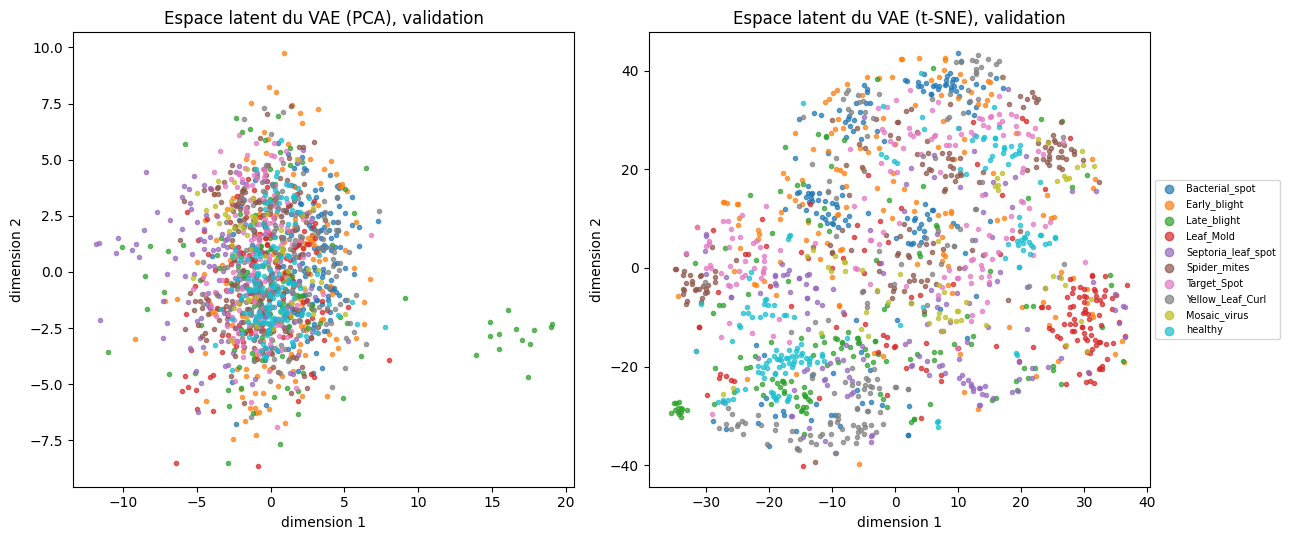

In [9]:
classes_courtes = [D.short(c) for c in D.CLASSES]
Z, etiquettes = [], []
for c in D.CLASSES:
    d = D.subset(df, split="val", classes=[c]).head(150)
    imgs = D.load_cache([C.resolve(p) for p in d["path"]], C.AE_SIZE)
    X = torch.from_numpy(np.array(imgs)).permute(0, 3, 1, 2).float().div(255).to(dev)
    with torch.no_grad():
        Z.append(vae.eval().encode(X)[0].cpu().numpy())
    etiquettes += [D.short(c)] * len(X)
Z, etiquettes = np.concatenate(Z), np.array(etiquettes)

proj = {"PCA": PCA(n_components=2, random_state=42).fit_transform(Z),
        "t-SNE": TSNE(n_components=2, random_state=42, init="pca", perplexity=30).fit_transform(Z)}

cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (nom, P) in zip(ax, proj.items()):
    for i, c in enumerate(classes_courtes):
        m = etiquettes == c
        a.scatter(P[m, 0], P[m, 1], s=9, color=cmap(i), alpha=.7, label=c)
    a.set_title(f"Espace latent du VAE ({nom}), validation"); a.set_xlabel("dimension 1"); a.set_ylabel("dimension 2")
ax[1].legend(fontsize=7, markerscale=2, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_vae_espace_latent.png", dpi=150, bbox_inches="tight"); plt.show()

### Ce qu'on observe

- **PCA.** Les classes sont presque toutes mélangées au centre, avec un petit groupe de Late_blight isolé à droite. Les deux premières directions ne suffisent pas à séparer les classes.
- **t-SNE.** On voit des zones : les feuilles **saines** (bleu-vert clair) sont surtout en bas à gauche, **Leaf_Mold** (rouge) en bas à droite et un petit groupe de Late_blight tout à gauche. Le reste (Bacterial_spot, Early_blight, Target_Spot, Spider_mites…) est mélangé.
- **Ce que cela veut dire.** Le VAE n'a jamais vu de feuille malade ni d'étiquette, et pourtant le code place les saines à part et certaines maladies en groupes. Le code `z` capte donc des régularités visibles. En revanche, il ne sépare pas les classes à lui seul : la plupart des maladies se recouvrent. Le t-SNE déforme les distances, donc on n'en tire que ces tendances.

## 5.5 Interpolations

- On prend deux feuilles, on encode chacune, puis on décode neuf points régulièrement répartis sur le segment qui relie leurs codes.
- Si l'espace latent est régulier, on voit la première feuille se transformer en douceur en la seconde, sans image absurde au milieu.
- Trois paires : deux saines, une saine et une malade, deux malades de classes différentes.

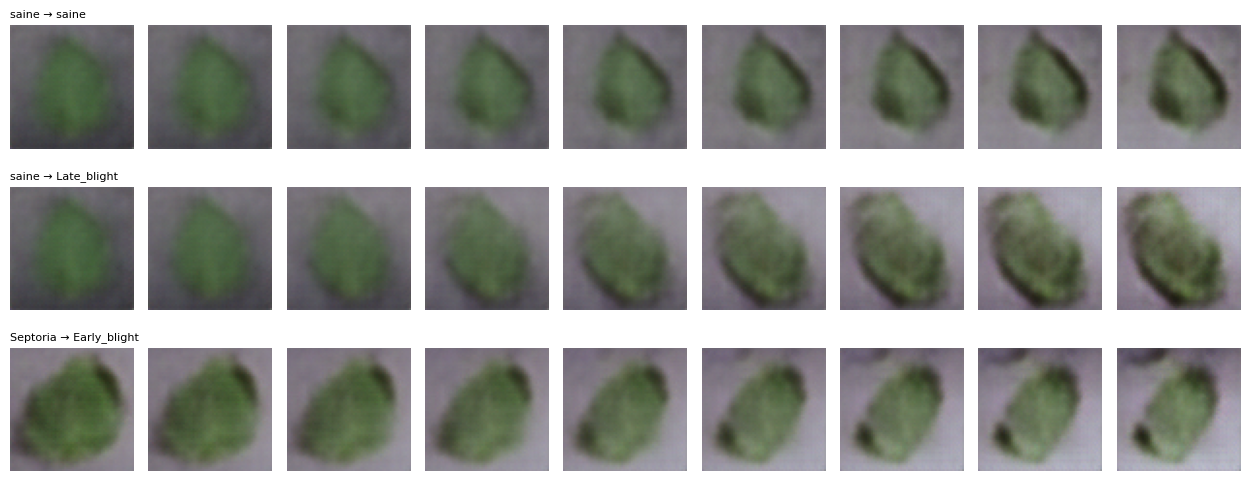

In [10]:
def une_image(split, classe, i=0):
    return load(split, [classe])[i:i + 1]

paires = [("saine → saine", X_val_h[3:4], X_val_h[120:121]),
          ("saine → Late_blight", X_val_h[3:4], une_image("val", "Tomato___Late_blight", 5)),
          ("Septoria → Early_blight", une_image("val", "Tomato___Septoria_leaf_spot", 5), une_image("val", "Tomato___Early_blight", 5))]

N_PAS = 9
fig, ax = plt.subplots(len(paires), N_PAS, figsize=(N_PAS * 1.4, len(paires) * 1.7))
with torch.no_grad():
    for r, (titre, a, b) in enumerate(paires):
        za, zb = vae.eval().encode(a)[0], vae.eval().encode(b)[0]
        for j, t in enumerate(np.linspace(0, 1, N_PAS)):
            img = vae.decoder((1 - t) * za + t * zb)
            ax[r, j].imshow(img[0].permute(1, 2, 0).cpu().numpy()); ax[r, j].axis("off")
        ax[r, 0].set_title(titre, fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_vae_interpolations.png", dpi=150, bbox_inches="tight"); plt.show()

### Ce qu'on observe

- **Les transitions sont progressives** : la feuille, sa forme et l'arrière-plan évoluent en douceur d'une extrémité à l'autre, sans image absurde au milieu. C'est ce qu'on attend d'un espace latent régulier.
- **Les extrémités sont floues** : ce sont les reconstructions décodées, pas les images d'origine.
- **Saine → Late_blight** : la feuille prend peu à peu une texture marbrée et un bord plus sombre. Cela montre que l'espace latent relie les deux images, pas que la transition est un modèle de la maladie. **Septoria → Early_blight** : les deux feuilles sont déjà abîmées, et la transition mélange leurs zones sombres.

## 5.6 Le VAE comme détecteur d'anomalies, comparé à l'auto-encodeur simple

- Même protocole que la partie 3 : seuil = 95e centile du score des feuilles saines de validation, c'est-à-dire environ 5 % de fausses alarmes attendues.
- L'auto-encodeur de référence est celui de la partie 3 (k = 16, `ae_best.pt`), avec son erreur de reconstruction.
- **C'est ici qu'on regarde le test, une seule fois.**

In [11]:
ae = build_ae(16).to(dev)
ae.load_state_dict(torch.load(C.CKPT_DIR / "ae_best.pt", map_location=dev))
ae.eval()

@torch.no_grad()
def ae_scores(X):
    return torch.cat([((ae(X[i:i + 256]) - X[i:i + 256]) ** 2).mean(dim=(1, 2, 3)) for i in range(0, len(X), 256)]).cpu().numpy()

def score_vae(X):
    return vae_scores(vae, X, BETA_BEST)[SCORE_BEST]

systemes = {"AE simple (k=16)": ae_scores, f"VAE (β={BETA_BEST}, {SCORE_BEST})": score_vae}
seuils = {nom: float(np.percentile(f(X_val_h), 95)) for nom, f in systemes.items()}
print("Seuils (95e centile des saines de validation) :", {k: round(v, 5) for k, v in seuils.items()})

X_test_h = load("test", [healthy])
test_malades = {c: load("test", [c]) for c in diseased}
X_test_d = torch.cat(list(test_malades.values()))

resultats = {}
for nom, f in systemes.items():
    sh, sd = f(X_test_h), f(X_test_d)
    resultats[nom] = {"auroc": auroc(sh, sd), "rappel": float((sd > seuils[nom]).mean()), "fausses_alarmes": float((sh > seuils[nom]).mean()),
                      "rappel_maladie": {D.short(c): float((f(X) > seuils[nom]).mean()) for c, X in test_malades.items()}}

print(f"{'système':>26s} {'AUROC':>7s} {'rappel malades':>15s} {'fausses alarmes':>16s}")
for nom, r in resultats.items():
    print(f"{nom:>26s} {r['auroc']:>7.3f} {r['rappel']:>15.3f} {r['fausses_alarmes']:>16.3f}")

Seuils (95e centile des saines de validation) : {'AE simple (k=16)': 0.01405, 'VAE (β=0.1, kl)': 88.15968}
                   système   AUROC  rappel malades  fausses alarmes
          AE simple (k=16)   0.628           0.201            0.084
           VAE (β=0.1, kl)   0.801           0.397            0.084


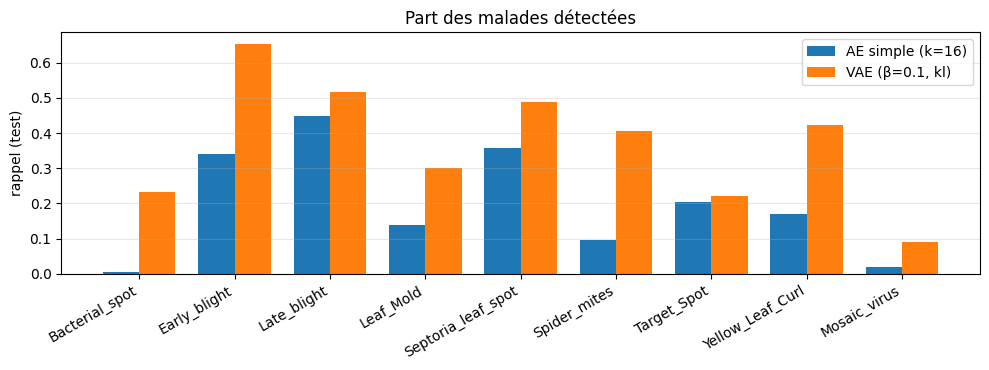

In [14]:
maladies = list(next(iter(resultats.values()))["rappel_maladie"])
x = np.arange(len(maladies))
plt.figure(figsize=(10, 3.8))
for i, (nom, r) in enumerate(resultats.items()):
    plt.bar(x + (i - .5) * .38, [r["rappel_maladie"][m] for m in maladies], .38, label=nom)
plt.xticks(x, maladies, rotation=30, ha="right"); plt.ylabel("rappel (test)")
plt.title("Part des malades détectées"); plt.legend(); plt.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_rappel_par_maladie.png", dpi=150, bbox_inches="tight"); plt.show()

### Ce qu'on observe sur le test

| Système | AUROC | Rappel malades | Fausses alarmes |
|---|---|---|---|
| AE simple (k = 16) | 0,628 | 0,201 | 0,084 |
| VAE (β = 0,1, KL) | **0,801** | **0,397** | 0,084 |

- **À fausses alarmes égales (8,4 %), le VAE détecte presque deux fois plus de malades** (39,7 % contre 20,1 %), et son AUROC passe de 0,63 à 0,80. Les valeurs de validation (0,802) et de test (0,801) sont très proches : le choix de β et du score n'est pas sur-ajusté.
- **Le gain est général** : le VAE fait mieux que l'auto-encodeur sur les 9 maladies, surtout sur Bacterial_spot (de 0 à 0,23), Spider_mites (de 0,10 à 0,41) et Early_blight (de 0,34 à 0,65). Les maladies les moins détectées restent Mosaic_virus (0,09), Target_Spot (0,22) et Bacterial_spot (0,23).
- **Cela reste insuffisant seul** : 60 % des feuilles malades passent sous le seuil. Comme à la partie 3, un détecteur de ce type ne peut pas remplacer un classifieur ; il peut servir de signal complémentaire.
- **Réserve.** Le seuil du VAE (88) est exprimé en unités de KL, donc il dépend de β : un autre β donnerait un autre seuil. Une seule graine, un seul entraînement par β : on n'a pas mesuré la variabilité entre répétitions.

- On enregistre le VAE retenu (poids et métadonnées, au format de `load_ae`) et une ligne dans `results/summary.csv`.

In [13]:
nom_vae = f"VAE (β={BETA_BEST}, {SCORE_BEST})"
r = resultats[nom_vae]
torch.save({"model": vae.state_dict(), "meta": {"type": "vae", "k": K, "beta": BETA_BEST, "score": SCORE_BEST}}, C.CKPT_DIR / "vae_best.pt")
C.save_json({"beta": BETA_BEST, "score": SCORE_BEST, "k": K, "threshold_p95": seuils[nom_vae],
             "auroc_val": {f"{b}_{s}": a for (b, s), a in auc_val.items()}}, C.RESULTS / "thresholds_vae.json")

taille = sum(t.numel() * t.element_size() for t in vae.state_dict().values()) / 1e6
upsert_summary({"experiment": f"P5_VAE_k{K}", "partie": 5, "modele": "VAE",
                "hyperparametres": f"k = {K}, β = {BETA_BEST}, score {SCORE_BEST}, Adam lr={LR}, batch {BATCH}, {EPOCHS} époques",
                "resolution": 64, "params": sum(p.numel() for p in vae.parameters()), "taille_mo": round(taille, 2),
                "temps_entrainement_s": round(times[BETA_BEST], 1),
                "test_auroc": round(r["auroc"], 4), "test_rappel_anomalies": round(r["rappel"], 4),
                "test_fausses_alarmes": round(r["fausses_alarmes"], 4)})
print("Ligne P5_VAE ajoutée à results/summary.csv")

Ligne P5_VAE ajoutée à results/summary.csv


## Conclusion de la partie 5

- **Génération.** Le VAE produit des feuilles floues et peu variées. Elles ne sont pas réalistes, mais l'espace latent est régulier : les interpolations passent d'une feuille à l'autre sans image absurde. Le coefficient β règle le compromis entre netteté (β petit) et régularité (β grand).
- **Espace latent.** Sans voir de malades ni d'étiquettes, le code sépare partiellement les feuilles saines de certaines maladies (Leaf_Mold, un groupe de Late_blight). Les autres maladies restent mélangées.
- **Détection d'anomalies.** Le score KL du VAE (AUROC test 0,80, rappel 39,7 % à 8,4 % de fausses alarmes) détecte nettement mieux que l'erreur de reconstruction de l'auto-encodeur simple (0,63 ; 20,1 %). Le gain est général, mais 60 % des malades restent non détectées.
- **Limites.** Une seule graine, trois valeurs de β, images en 64×64. Nous ne savons pas pourquoi le KL est un meilleur score : l'explication par la lésion plutôt que par le fond n'est pas testée. Le meilleur β pour détecter (0,1) n'est pas le meilleur pour générer (1).